# Fallo de baterías: el modelo que leía el parte del taller

**Avanzado · Jornada 2 · Bloques 2.3 y 2.5 · diapositivas reto, demo-fuga, fuga, desbalance, matriz-confusion, umbral-coste, calibracion, censura, km-paso-a-paso, kaplan-meier, ejercicio-baterias, permutacion, shap y reto-presentar**

¿Qué baterías deben pasar por el taller antes de fallar, y cuándo fallarán? Cazamos una fuga de información, elegimos el umbral con dinero, usamos bien la censura y explicamos por qué una bici concreta está en la lista de 50.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## 1. La pregunta

BiciCiudad tiene 2.000 bicis en servicio y el taller solo puede revisar **50 esta semana**. ¿Cuáles? Es el
reto del día: una lista de 50 defendida con un criterio, un umbral y lo que cuesta equivocarse.

Para llegar ahí: un modelo de riesgo que no haga trampa, un umbral elegido con dinero y, después, la
pregunta completa: no solo si fallará, sino cuándo.

> **Mensaje clave del bloque:** la pregunta «¿se romperá?» es incompleta; la buena es «¿cuándo, y cuánto
> cuesta equivocarse?».

In [2]:
# Tres ayudas de formato en español.
import warnings

warnings.filterwarnings("ignore")  # avisos de convergencia y de versiones: no cambian los resultados


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha como en las diapositivas: 18-5-2026."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"

In [3]:
import itertools
import math

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, average_precision_score, precision_recall_curve
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.duration.survfunc import SurvfuncRight
from threadpoolctl import threadpool_limits

_ = threadpool_limits(2)   # dos hilos: el boosting va más deprisa que peleando por todos los núcleos

## 2. El panel de baterías

Una foto al mes de cada batería activa: edad, ciclos, capacidad medida, profundidad de descarga, cargas
rápidas, horas de calor, avisos de su sistema de gestión (BMS), modelo, lote de firmware… y la etiqueta
`fallo_90d`: si falló en servicio en los 90 días siguientes.

In [4]:
panel = pd.read_parquet(DATOS / "panel_baterias" / "panel.parquet")
print(f"{n(len(panel))} fotos, de {panel['mes'].min()} a {panel['mes'].max()}")

sin_etiqueta = panel[panel["fallo_90d"].isna()]["mes"].value_counts().sort_index()
print("Meses sin etiqueta (aún no han pasado 90 días al cierre del 30-9-2026):", ", ".join(sin_etiqueta.index))
panel.head(3).T

351.000 fotos, de 2023-07 a 2026-09
Meses sin etiqueta (aún no han pasado 90 días al cierre del 30-9-2026): 2026-08, 2026-09


,0,1,2
mes,2023-07,2023-07,2023-07
bateria_id,BAT-00001,BAT-00002,BAT-00004
bici_id,BC-0224,BC-0237,BC-1496
base_id,B-29,B-03,B-39
modelo,BX-450,BX-450,BX-450
generacion,1,1,1
lote_firmware,FW-1.4,FW-1.4,FW-1.4
edad_meses,28,28,28
ciclos_acumulados,1111.0,1004.0,801.0
ciclos_ultimo_mes,44,39,48


In [5]:
# Las variables de texto, a números para el boosting; y la etiqueta, a 0/1
for c in ("modelo", "lote_firmware"):
    panel[c + "_cod"] = panel[c].astype("category").cat.codes
VARIABLES = ["edad_meses", "ciclos_acumulados", "ciclos_ultimo_mes", "capacidad_pct", "profundidad_descarga_pct",
             "cargas_rapidas_pct", "horas_calor_mes", "avisos_bms_30d", "modelo_cod", "lote_firmware_cod"]

etiquetado = panel[panel["fallo_90d"].notna()].copy()
etiquetado["y"] = etiquetado["fallo_90d"].astype(int)
print(f"Fotos con fallo en los 90 días siguientes: {pct(etiquetado['y'].mean())}")

Fotos con fallo en los 90 días siguientes: 1,6 %


## 3. Demo: un 99,3 % de exactitud. Buscad el truco

Un boosting con las diez variables y una más, `orden_taller_sustitucion`. Ya con corte temporal, como en el
bloque anterior: entrena hasta junio de 2025 y se examina con todo lo etiquetado desde julio de 2025 (de
julio de 2025 a julio de 2026; es el periodo de prueba del cálculo de las diapositivas).

In [6]:
entreno = etiquetado[etiquetado["mes"] <= "2025-06"]
prueba = etiquetado[etiquetado["mes"] >= "2025-07"]


def clasificador():
    # Los mismos ajustes que el cálculo de las diapositivas
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=2026)


con_fuga = VARIABLES + ["orden_taller_sustitucion"]
modelo_fuga = clasificador().fit(entreno[con_fuga], entreno["y"])
prob_fuga = modelo_fuga.predict_proba(prueba[con_fuga])[:, 1]

print(f"Exactitud: {pct(accuracy_score(prueba['y'], prob_fuga >= 0.5))}")
print(f"PR-AUC: {n(average_precision_score(prueba['y'], prob_fuga), 2)}")

Exactitud: 99,3 %
PR-AUC: 0,77


**Parad aquí.** ¿Qué variable de la lista no podría conocerse antes de que la batería falle? Pensadlo antes de
ejecutar la celda siguiente.

In [7]:
# La orden de taller, según haya fallo o no en los 90 días siguientes
reparto = etiquetado.groupby("y")["orden_taller_sustitucion"].mean()
print(f"Fotos con fallo: la orden vale 1 en el {pct(reparto[1], 0)}")
print(f"Fotos sin fallo: vale 1 en el {pct(reparto[0], 2)} (sustituciones preventivas)")

Fotos con fallo: la orden vale 1 en el 78 %
Fotos sin fallo: vale 1 en el 0,36 % (sustituciones preventivas)


La orden de sustitución se abre **después** del fallo, pero la tabla del taller se cruzó por batería sin
mirar la fecha. El modelo no predecía: leía el parte del taller. Es una **fuga de información**. La quitamos:

In [8]:
modelo = clasificador().fit(entreno[VARIABLES], entreno["y"])
prob = modelo.predict_proba(prueba[VARIABLES])[:, 1]
y = prueba["y"].to_numpy()

pr_auc = average_precision_score(y, prob)
print(f"Sin la orden de taller: PR-AUC {n(pr_auc, 2)}, exactitud {pct(accuracy_score(y, prob >= 0.5))}")
print(f"El azar (la prevalencia en la prueba): {n(y.mean(), 3)}. El modelo honesto da {n(pr_auc / y.mean(), 0)} veces el azar.")

Sin la orden de taller: PR-AUC 0,25, exactitud 98,5 %
El azar (la prevalencia en la prueba): 0,016. El modelo honesto da 15 veces el azar.


## 4. Decir siempre «no falla» ya acierta el 98,4 %

Con un 1,6 % de fallos, la exactitud no sirve. Hay que mirar la **sensibilidad** (de los fallos que hubo,
cuántos encontramos) y la **precisión** (de los avisos que dimos, cuántos eran fallos).

In [9]:
print(f"Modelo perezoso, siempre «no falla»: {pct(1 - etiquetado['y'].mean())} de exactitud")

precision, sensibilidad, umbrales_pr = precision_recall_curve(y, prob)
# Como el gráfico de la diapositiva, leemos la curva con unos 120 umbrales (un punto de cada `paso`)
paso = max(len(precision) // 120, 1)
for objetivo in (0.1, 0.3, 0.5, 0.8):
    i = np.abs(sensibilidad[::paso] - objetivo).argmin()
    print(f"Para encontrar el {pct(objetivo, 0)} de los fallos, aciertan {n(100 * precision[::paso][i])} de cada 100 avisos")

Modelo perezoso, siempre «no falla»: 98,4 % de exactitud
Para encontrar el 10 % de los fallos, aciertan 97 de cada 100 avisos
Para encontrar el 30 % de los fallos, aciertan 24 de cada 100 avisos
Para encontrar el 50 % de los fallos, aciertan 6 de cada 100 avisos
Para encontrar el 80 % de los fallos, aciertan 2 de cada 100 avisos


## 5. El umbral lo pone la matriz de costes, no el 0,5

Costes supuestos para el ejercicio (no son datos reales):

| | Falla | No falla |
| --- | --- | --- |
| **Se revisa** | 40 € (se evita el fallo) | 40 € (revisión inútil) |
| **No se revisa** | 400 € (usuario tirado) | 0 € |

Cambiad el umbral y mirad el coste total del periodo de prueba.

In [10]:
COSTE_REVISION, COSTE_FALLO = 40, 400


def coste(umbral):
    revisar = prob >= umbral
    fallos_sin_revisar = ((~revisar) & (y == 1)).sum()
    return COSTE_REVISION * revisar.sum() + COSTE_FALLO * fallos_sin_revisar, revisar.sum(), fallos_sin_revisar


umbral = 0.5   # ← probad otros: 0,05, 0,1, 0,2…
total, revisiones, escapados = coste(umbral)
print(f"Umbral {n(umbral, 2)}: {n(revisiones)} revisiones, {n(escapados)} fallos sin revisar, {n(total)} €")
print(f"Sin modelo, sin revisar nada: {n(COSTE_FALLO * y.sum())} €")

Umbral 0,50: 405 revisiones, 1.630 fallos sin revisar, 668.200 €
Sin modelo, sin revisar nada: 770.000 €


**La matriz de confusión.** Con un umbral, cada foto cae en una de cuatro casillas: avisa y falla (acierto),
avisa y no falla (revisión inútil), no avisa y falla (se escapa) y no avisa y no falla. De ahí salen la
exactitud, la precisión, la sensibilidad y el coste.

In [11]:
def matriz(umbral):
    avisa = prob >= umbral
    return pd.DataFrame({"falla": [(avisa & (y == 1)).sum(), (~avisa & (y == 1)).sum()],
                         "no falla": [(avisa & (y == 0)).sum(), (~avisa & (y == 0)).sum()]},
                        index=["avisa", "no avisa"])


m = matriz(0.5)   # ← probad 0,15
acierto, inutil = m.loc["avisa", "falla"], m.loc["avisa", "no falla"]
escapa, descartada = m.loc["no avisa", "falla"], m.loc["no avisa", "no falla"]
total = int(m.to_numpy().sum())
print(f"Exactitud = ({n(acierto)} + {n(descartada)}) ÷ {n(total)} = {pct((acierto + descartada) / total)}")
print(f"Precisión = {n(acierto)} ÷ {n(acierto + inutil)} = {pct(acierto / (acierto + inutil), 0)}")
print(f"Sensibilidad = {n(acierto)} ÷ {n(acierto + escapa)} = {pct(acierto / (acierto + escapa), 0)}")
print(f"Coste = 40 × {n(acierto + inutil)} + 400 × {n(escapa)} = {n(40 * (acierto + inutil) + 400 * escapa)} €")
m

Exactitud = (295 + 114.965) ÷ 117.000 = 98,5 %
Precisión = 295 ÷ 405 = 73 %
Sensibilidad = 295 ÷ 1.925 = 15 %
Coste = 40 × 405 + 400 × 1.630 = 668.200 €


,falla,no falla
avisa,295,110
no avisa,1630,114965


Si el modelo estuviera bien calibrado, el umbral óptimo sería el cociente de costes, 40 / 400 = 0,1. Por eso
hay que mirar la calibración.

## 6. Si el modelo dice 30 %, deben fallar 3 de cada 10

Ordenamos las fotos de la prueba por la probabilidad que da el modelo, las partimos en diez grupos iguales
(deciles) y comparamos la probabilidad media con la proporción que falló de verdad.

In [12]:
deciles = pd.qcut(prob, 10, labels=False, duplicates="drop") + 1
calibracion = pd.DataFrame({"decil": deciles, "prob": prob, "fallo": y}).groupby("decil").agg(
    probabilidad_media=("prob", "mean"), fallan_de_verdad=("fallo", "mean"), fotos=("fallo", "size"))
(100 * calibracion[["probabilidad_media", "fallan_de_verdad"]]).round(2)

,probabilidad_media,fallan_de_verdad
decil,,
1,0.59,0.61
2,0.73,0.67
3,0.81,0.70
4,0.87,0.71
5,0.95,1.10
6,1.08,1.15
7,1.22,0.98
8,1.42,1.33
9,1.86,1.61


En nueve deciles la probabilidad media no llega al 2 % y los puntos están pegados a la realidad. El más alto
dice un 8,5 % y fallan un 7,6 %: exagera un poco el riesgo, por eso el óptimo sale algo por encima de 0,1.
Si entrenáis reequilibrando las clases a mano, recalibrad después (por ejemplo, con una regresión isotónica
sobre un periodo de validación).

## 7. Las baterías que no han fallado no son buenas: son «todavía no»

Ahora, la pregunta del cuándo, con el inventario: cada batería con su alta y, si la tiene, su baja. Las que
siguen activas el 30-9-2026 están **censuradas**: sabemos que han vivido al menos hasta ese día.

In [13]:
inventario = pd.read_csv(DATOS / "inventario_baterias" / "baterias.csv", parse_dates=["fecha_alta", "fecha_baja"])
CIERRE = pd.Timestamp("2026-09-30")

fin = inventario["fecha_baja"].fillna(CIERRE)                       # las activas, hasta el cierre
inventario["meses"] = ((fin - inventario["fecha_alta"]).dt.days / 30.44).round(1)
inventario["baja"] = inventario["fecha_baja"].notna().astype(int)   # 1 = fallo o degradación; 0 = censurada

print(f"{n(len(inventario))} baterías; {n((inventario['baja'] == 0).sum())} siguen activas (censuradas)")
inventario.groupby(["modelo", "lote_firmware"]).agg(baterias=("baja", "size"), dadas_de_baja=("baja", "mean")).round(2)

18.383 baterías; 8.734 siguen activas (censuradas)


baterias  dadas_de_baja
modelo lote_firmware                         
BX-450 FW-1.4             9615           0.83
BX-600 FW-2.0              757           0.22
       FW-2.1             1515           0.79
       FW-2.2             3529           0.05
BX-750 FW-2.2             2967           0.04

La trampa: calcular la vida media solo con las que ya han caído. Mirad qué lote parecería el peor.

In [14]:
ingenua = inventario[inventario["baja"] == 1].groupby("lote_firmware")["meses"].mean()
print("Vida media de las que ya han caído, por lote (¡mal hecho!):")
print(ingenua.round(1).to_string())

Vida media de las que ya han caído, por lote (¡mal hecho!):
lote_firmware
FW-1.4    41.7
FW-2.0    24.8
FW-2.1    19.3
FW-2.2     7.0


**Kaplan-Meier a mano** con las diez BX-600 de la diapositiva de la censura: S = Π (1 − caídas ÷ en riesgo).
En cada caída se multiplica por la parte que no cae de las que seguían en observación; las activas cuentan
mientras están y salen sin bajar la curva.

In [15]:
diez = ["BAT-10082", "BAT-10162", "BAT-10473", "BAT-10607", "BAT-10788",
        "BAT-11819", "BAT-11804", "BAT-11686", "BAT-11980", "BAT-12132"]
km = inventario[inventario["bateria_id"].isin(diez)].sort_values("meses")[["bateria_id", "lote_firmware", "meses", "baja"]]
km["en_riesgo"] = np.arange(len(km), 0, -1)
km["factor"] = np.where(km["baja"] == 1, 1 - 1 / km["en_riesgo"], 1.0)
km["sigue"] = km["factor"].cumprod()
print(f"Media de las que han caído: {n(km.loc[km['baja'] == 1, 'meses'].sum(), 1)} ÷ {km['baja'].sum()} = "
      f"{n(km.loc[km['baja'] == 1, 'meses'].mean(), 1)} meses")
print(f"Vida mediana (Kaplan-Meier): {n(km.loc[km['sigue'] <= 0.5, 'meses'].iloc[0], 1)} meses")
km.round(2)

Media de las que han caído: 65,2 ÷ 5 = 13,0 meses
Vida mediana (Kaplan-Meier): 20,7 meses


,bateria_id,lote_firmware,meses,baja,en_riesgo,factor,sigue
10787,BAT-10788,FW-2.1,3.6,1,10,0.90,0.9
11685,BAT-11686,FW-2.1,9.7,1,9,0.89,0.8
11803,BAT-11804,FW-2.1,11.7,1,8,0.88,0.7
12131,BAT-12132,FW-2.2,19.5,1,7,0.86,0.6
10606,BAT-10607,FW-2.1,20.7,1,6,0.83,0.5
11979,BAT-11980,FW-2.2,23.1,0,5,1.00,0.5
11818,BAT-11819,FW-2.1,24.8,0,4,1.00,0.5
10472,BAT-10473,FW-2.1,31.9,0,3,1.00,0.5
10161,BAT-10162,FW-2.0,34.3,0,2,1.00,0.5
10081,BAT-10082,FW-2.0,35.4,0,1,1.00,0.5


Según esa cuenta, el lote más nuevo, FW-2.2, «dura» solo 7 meses: es el peor. Mentira: de un lote que empezó
en octubre de 2024 solo han podido caer las que cayeron pronto. Las que siguen vivas, que son casi todas, no
cuentan. **Kaplan-Meier** las usa bien: cuentan mientras están en observación y salen sin hacer bajar la curva.

## 8. Kaplan-Meier por modelo y lote, y el modelo de Cox

In [16]:
def vida_mediana(grupo):
    curva = SurvfuncRight(grupo["meses"], grupo["baja"])
    cayo_la_mitad = curva.surv_prob <= 0.5
    return curva.surv_times[cayo_la_mitad][0] if cayo_la_mitad.any() else np.nan   # nan: aún no ha llegado


medianas = inventario.groupby(["modelo", "lote_firmware"])[["meses", "baja"]].apply(vida_mediana)
print("Vida mediana en meses (NaN = aún no ha caído la mitad):")
print(medianas.round(1).to_string())

Vida mediana en meses (NaN = aún no ha caído la mitad):
modelo  lote_firmware
BX-450  FW-1.4           46.8
BX-600  FW-2.0            NaN
        FW-2.1           21.9
        FW-2.2            NaN
BX-750  FW-2.2            NaN


Para comparar grupos teniendo en cuenta la censura se usa el **modelo de Cox**. Dentro de las BX-600, el lote
FW-2.1 frente a los otros dos:

In [17]:
bx600 = inventario[inventario["modelo"] == "BX-600"]
es_fw21 = (bx600["lote_firmware"] == "FW-2.1").astype(float).to_numpy()[:, None]
cox = PHReg(bx600["meses"].to_numpy(), es_fw21, status=bx600["baja"].to_numpy()).fit()

riesgo = np.exp(cox.params[0])
bajo, alto = np.exp(cox.conf_int()[0])
print(f"Cociente de riesgos de FW-2.1: {n(riesgo, 1)} (IC 95 % de {n(bajo, 1)} a {n(alto, 1)})")

Cociente de riesgos de FW-2.1: 8,6 (IC 95 % de 7,5 a 9,9)


En cualquier mes, una FW-2.1 tiene unas ocho veces y media más riesgo de caer que una BX-600 de otro lote:
la mitad ha caído a los 22 meses, frente a los 47 de la primera generación.

## 9. Ejercicio (parejas, 20 min): vida mediana por modelo y el umbral de menor coste

**Tarea 1.** Kaplan-Meier para BX-450, BX-600 y BX-750, con las activas como censuradas. ¿Qué modelo no ha
llegado aún a su mediana? ¿Qué diríais de él?

In [18]:
agrupar_por = "lote_firmware"   # COMPLETAD: la tarea pide la vida mediana por "modelo"

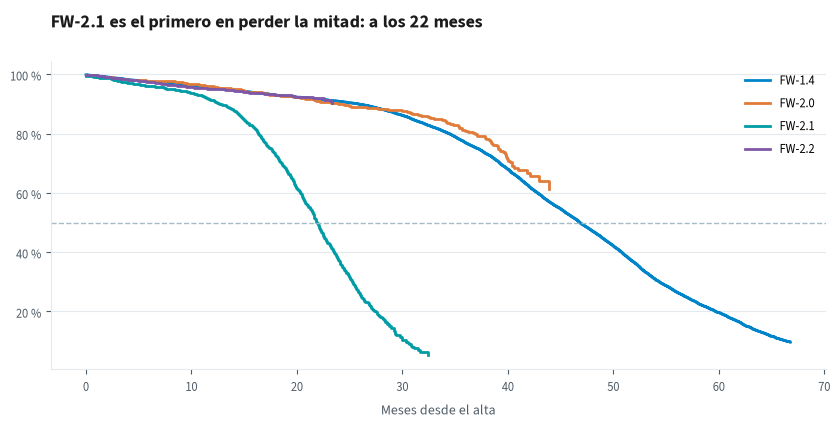

Vida mediana en meses (NaN = aún no ha caído la mitad):
FW-1.4    46.8
FW-2.0     NaN
FW-2.1    21.9
FW-2.2     NaN


In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
resumen = {}
for nombre, grupo in inventario.groupby(agrupar_por):
    curva = SurvfuncRight(grupo["meses"], grupo["baja"])
    ax.step(curva.surv_times, curva.surv_prob, where="post", label=nombre)
    resumen[nombre] = vida_mediana(grupo)
resumen = pd.Series(resumen)

primero = resumen.idxmin()
ax.axhline(0.5, color=estilo.GRIS, linestyle="--", linewidth=1)
ax.set_title(f"{primero} es el primero en perder la mitad: a los {n(resumen.min())} meses")
ax.set_xlabel("Meses desde el alta")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{n(100 * v)} %"))
ax.legend()
plt.show()
print("Vida mediana en meses (NaN = aún no ha caído la mitad):")
print(resumen.round(1).to_string())

**Tarea 2.** Con el modelo sin fuga, calculad el coste total para cada umbral de 0,01 a 0,50 y elegid el más
barato. Comparadlo con el 0,5.

In [20]:
umbrales = [0.5]   # COMPLETAD: todos los umbrales de 0,01 a 0,50 (pista: np.arange)

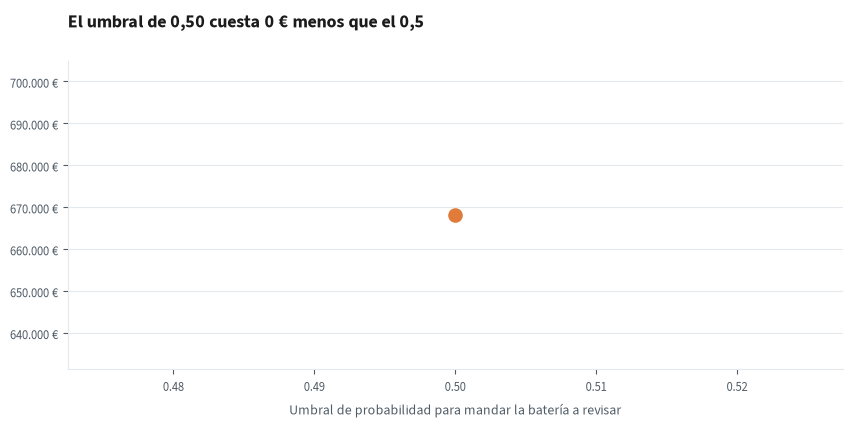

Mínimo: umbral 0,50, 668.200 € con 405 revisiones
Con 0,5: 668.200 €. Sin modelo: 770.000 €


In [21]:
costes = pd.DataFrame([(u, *coste(u)) for u in umbrales],
                      columns=["umbral", "coste_eur", "revisiones", "fallos_sin_revisar"])
mejor = costes.loc[costes["coste_eur"].idxmin()]
con_05 = coste(0.5)[0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(costes["umbral"], costes["coste_eur"], color=estilo.AZUL, marker="o", markersize=3)
ax.scatter([mejor["umbral"]], [mejor["coste_eur"]], s=90, color=estilo.NARANJA, zorder=3)
ax.set_title(f"El umbral de {n(mejor['umbral'], 2)} cuesta {n(con_05 - mejor['coste_eur'])} € menos que el 0,5")
ax.set_xlabel("Umbral de probabilidad para mandar la batería a revisar")
estilo.formato_eje(ax, sufijo=" €")
plt.show()
print(f"Mínimo: umbral {n(mejor['umbral'], 2)}, {n(mejor['coste_eur'])} € con {n(mejor['revisiones'])} revisiones")
print(f"Con 0,5: {n(con_05)} €. Sin modelo: {n(COSTE_FALLO * y.sum())} €")

## 10. Explicar el modelo: qué mira (permutación)

Barajamos cada variable en el periodo de prueba, como quien mezcla las cartas, y medimos cuánto cae la PR-AUC.
Si el modelo se queda ciego, la variable importaba.

In [22]:
muestra = prueba.sample(40_000, random_state=2026)   # una muestra, para que tarde segundos
perm = permutation_importance(modelo, muestra[VARIABLES], muestra["y"], scoring="average_precision",
                              n_repeats=3, random_state=2026)
importancia = pd.Series(perm.importances_mean, index=VARIABLES).sort_values(ascending=False)
importancia.round(3)

avisos_bms_30d              0.240
edad_meses                  0.037
capacidad_pct               0.013
ciclos_acumulados           0.009
horas_calor_mes             0.003
profundidad_descarga_pct    0.003
cargas_rapidas_pct          0.003
lote_firmware_cod           0.001
ciclos_ultimo_mes           0.000
modelo_cod                 -0.000
dtype: float64

Los avisos del BMS pesan más que todo lo demás junto. El lote FW-2.1 sale casi sin importancia: no contradice
a Kaplan-Meier. Sus baterías se degradan antes, y eso ya se ve en la capacidad y en los avisos; con los
síntomas, la etiqueta del lote añade poco. Importancia no es causalidad.

## 11. Explicar una bici: valores de Shapley

Para la lista del reto usamos el modelo sin fuga entrenado con **todo** lo etiquetado y la última foto,
septiembre de 2026. Los valores de Shapley reparten la diferencia entre la probabilidad de una bici y la media
entre sus variables, probando todas las combinaciones (con diez variables, 1.024: se pueden calcular exactos).

In [23]:
modelo_final = clasificador().fit(etiquetado[VARIABLES], etiquetado["y"])
ultima_foto = panel[(panel["mes"] == "2026-09") & (panel["bici_id"] != "")].copy()   # bicis en servicio

bici_elegida = "BC-0924"   # ← probad otra bici de vuestra lista
fila = ultima_foto[ultima_foto["bici_id"] == bici_elegida].iloc[0]
x = fila[VARIABLES].to_numpy(dtype=float)
fondo = etiquetado[VARIABLES].sample(200, random_state=2026).to_numpy(dtype=float)   # 200 fotos de referencia


def valor(coalicion):
    # Probabilidad media si las variables de la coalición toman el valor de esta bici y el resto, el del fondo
    z = fondo.copy()
    z[:, list(coalicion)] = x[list(coalicion)]
    return modelo_final.predict_proba(pd.DataFrame(z, columns=VARIABLES))[:, 1].mean()


k = len(VARIABLES)
valores = {c: valor(c) for r in range(k + 1) for c in itertools.combinations(range(k), r)}
shapley = np.zeros(k)
for i in range(k):
    for c, v in valores.items():
        if i not in c:
            peso = math.factorial(len(c)) * math.factorial(k - len(c) - 1) / math.factorial(k)
            shapley[i] += peso * (valores[tuple(sorted(c + (i,)))] - v)

base, final = valores[()], valores[tuple(range(k))]
print(f"{bici_elegida} ({fila['bateria_id']}, {fila['modelo']} {fila['lote_firmware']}): "
      f"de la media, {pct(base)}, a {pct(final)}")
pd.DataFrame({"valor": x, "puntos": 100 * shapley}, index=VARIABLES).sort_values(
    "puntos", key=abs, ascending=False).round(1)

BC-0924 (BAT-15528, BX-600 FW-2.2): de la media, 1,2 %, a 84,8 %


,valor,puntos
avisos_bms_30d,4.0,79.5
edad_meses,10.0,2.1
capacidad_pct,95.1,1.3
cargas_rapidas_pct,18.0,-0.9
profundidad_descarga_pct,70.0,0.7
ciclos_acumulados,382.0,0.5
horas_calor_mes,21.0,0.3
ciclos_ultimo_mes,36.0,0.2
modelo_cod,1.0,0.0
lote_firmware_cod,3.0,-0.0


Casi todo es una sola cosa: sus cuatro avisos del BMS en el último mes. Es algo que el jefe de taller puede
comprobar: si le dicen «esa batería la cambiamos ayer», la bici sale de la lista. Shapley explica el modelo,
no la batería.

## 12. Reto: vuestra lista de 50

El criterio de partida es ingenuo: las 50 baterías más viejas. Cambiadlo por el riesgo del modelo sin fuga.

In [24]:
ultima_foto["riesgo"] = ultima_foto["edad_meses"]   # COMPLETAD: usad la probabilidad de modelo_final
lista = ultima_foto.sort_values("riesgo", ascending=False).head(50)

In [25]:
# Lo que se espera ganar o perder con esta lista, en euros: cada revisión cuesta 40 €;
# cada fallo que se evita ahorra 400 €. Los fallos esperados son la suma de las probabilidades del modelo.
prob_lista = modelo_final.predict_proba(lista[VARIABLES])[:, 1]
ahorro = COSTE_FALLO * prob_lista.sum() - COSTE_REVISION * len(lista)
print(f"Fallos esperados en las 50: {n(prob_lista.sum(), 1)}; revisarlas cuesta {n(COSTE_REVISION * len(lista))} €")
print(f"Saldo esperado: {n(ahorro)} €")
print(f"Baterías del lote FW-2.1 en la lista: {(lista['lote_firmware'] == 'FW-2.1').sum()}")
lista[["bici_id", "bateria_id", "modelo", "lote_firmware", "capacidad_pct", "avisos_bms_30d"]].head(10)

Fallos esperados en las 50: 1,5; revisarlas cuesta 2.000 €
Saldo esperado: −1.407 €
Baterías del lote FW-2.1 en la lista: 0


,bici_id,bateria_id,modelo,lote_firmware,capacidad_pct,avisos_bms_30d
342000,BC-0934,BAT-00007,BX-450,FW-1.4,71.5,0
342347,BC-1801,BAT-03239,BX-450,FW-1.4,72.3,0
342326,BC-0731,BAT-03039,BX-450,FW-1.4,70.6,0
342328,BC-1006,BAT-03056,BX-450,FW-1.4,79.7,1
342329,BC-1748,BAT-03066,BX-450,FW-1.4,73.1,0
342335,BC-0757,BAT-03100,BX-450,FW-1.4,71.4,1
342336,BC-1821,BAT-03132,BX-450,FW-1.4,71.9,0
342341,BC-0575,BAT-03172,BX-450,FW-1.4,78.4,1
342360,BC-0664,BAT-03390,BX-450,FW-1.4,80.2,1
342399,BC-1372,BAT-03665,BX-450,FW-1.4,71.9,2


## Qué os lleváis

- Ante un resultado brillante, preguntad **cuándo se conoce cada variable**: la orden de taller llegaba
  después del fallo. Sin ella, PR-AUC de 0,25: modesta, pero quince veces el azar.
- Con clases raras, la exactitud engaña: decir siempre «no falla» acierta el 98,4 %.
- El umbral lo pone la matriz de costes, no el 0,5; y las probabilidades solo sirven para eso si están
  calibradas.
- Las baterías que no han fallado son «todavía no»: Kaplan-Meier y Cox usan la censura; la media de las caídas,
  no.
- Explicad la lista con algo que el taller pueda comprobar.